In [1]:
%cd Error-State-Kalman-Filter-standalone/ 
!make clean 
!make libmain.so
%cd ..

/home/noah/NEXT/ESKF_shockwave_simulations/Error-State-Kalman-Filter-standalone
rm -rf build
gcc -Iinclude -Ithird_party/CMSIS-DSP/Include -Ithird_party/CMSIS_5/CMSIS/Core/Include -Wall -Wpedantic -MMD -MP -c src/ESKF_init.c -o build/src/ESKF_init.o
gcc -Iinclude -Ithird_party/CMSIS-DSP/Include -Ithird_party/CMSIS_5/CMSIS/Core/Include -Wall -Wpedantic -MMD -MP -c src/ESKF_predict.c -o build/src/ESKF_predict.o
src/ESKF_predict.c:244:12: warning: ‘predict_error_populate_Fx_second_order’ defined but not used []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wunused-function-Wunused-function]8;;]
  244 | static int predict_error_populate_Fx_second_order(ErrorStateKalmanFilter *self, float32_t delta_t_acc, float32_t delta_t_gyr) {
      |            ^~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
gcc -Iinclude -Ithird_party/CMSIS-DSP/Include -Ithird_party/CMSIS_5/CMSIS/Core/Include -Wall -Wpedantic -MMD -MP -c src/ESKF_update.c -o build/src/ESKF_update.o
src/ESKF_update.c:521:12

In [2]:


import time as time_module # coincides with a simulation variable
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sim_src.quaternion_math import quaternion_to_euler_angles, rotation_vector_to_quaternion, hamiltonian_product
from simulator import SPEED_OF_SOUND

GRAVITY = 9.8125

# noise in std dev
gns_nois = np.array([1.0]*3) *1e2  #m
bar_nois = np.array([1.0]) * 1e2# m
acc_nois = np.array([1.0]*3) * 1e0 #m/s^2 
gyr_nois = np.array([1.0]*3) * 1e-3 # m/s
mag_nois = np.array([1.0]*3) *1e2 # G


# running pure C ESKF
import ctypes
from estimator_wrap import library, Estimator, _as_float_array, _matrix_to_numpy


def load_measurements(): 
    gns_path = "rocketpysims/GNSS_data.csv"
    bar_path = "rocketpysims/barometer_data.csv"
    acc_path = "rocketpysims/accelerometer_data.csv"
    gyr_path = "rocketpysims/gyroscope_data.csv"
    gns = pd.read_csv(gns_path)
    bar = pd.read_csv(bar_path)
    acc = pd.read_csv(acc_path)
    gyr = pd.read_csv(gyr_path)
    meas = pd.merge(gns, bar, how="outer")
    meas = pd.merge(meas, acc, how="outer")
    meas = pd.merge(meas, gyr, how="outer")
    return meas

def load_grund_truth(): 
    return pd.read_csv("rocketpysims/ground_truth.csv")


In [3]:

def calculate_rms_error(true_position, true_velocity, true_attitude, estimated_position, estimated_velocity, estimated_attitude):
    """calculate post 'flight' rms error"""
    position_error = np.linalg.norm(true_position - estimated_position, axis=1)
    velocity_error = np.linalg.norm(true_velocity - estimated_velocity, axis=1)
    attitude_error_quat = np.linalg.norm(true_attitude - estimated_attitude, axis=1)
    
    true_euler_angles = np.array([quaternion_to_euler_angles(true_quaternion) for true_quaternion in true_attitude])
    estimated_euler_angles = np.array([quaternion_to_euler_angles(attitude) for attitude in estimated_attitude])
    euler_delta = (true_euler_angles - estimated_euler_angles + np.pi) % (2.0 * np.pi) - np.pi
    attitude_error_angle = np.linalg.norm(euler_delta, axis=1)
    
    rms_position_error = np.sqrt(np.mean(position_error**2))
    rms_velocity_error = np.sqrt(np.mean(velocity_error**2))
    rms_attitude_error_quat = np.sqrt(np.mean(attitude_error_quat**2))
    rms_attitude_error_angle = np.sqrt(np.mean(attitude_error_angle**2))
    
    return rms_position_error, rms_velocity_error, rms_attitude_error_quat, rms_attitude_error_angle

def run_ESKF_thorugh_data():

    measurements = load_measurements()
    ground_truth = load_grund_truth()

    # convert the noise arrays to c-compatible arrays
    gns_nois_c = _as_float_array(gns_nois)
    acc_nois_c = _as_float_array(acc_nois)
    gyr_nois_c = _as_float_array(gyr_nois)
    mag_nois_c = _as_float_array(mag_nois)
    bar_nois_c = _as_float_array(bar_nois)

    # initialize estimator
    est = Estimator()
    error = library.estimator_init(
        ctypes.byref(est),
        gns_nois_c,
        acc_nois_c,
        gyr_nois_c,
        mag_nois_c,
        bar_nois_c
    )
    if error: print(f"{error = }")

    # use the same reference as the simulator
    library.estimator_set_reference(
        ctypes.byref(est),
        ctypes.c_float(0.0),              # reference_height
        ctypes.c_float(69.6489),      # reference_latitude
        ctypes.c_float(18.95508),    # reference_longitude
    )


    est.eskf.nominal_state.pData[6] = ground_truth["qw"][0] + np.random.normal(0.0, 0.01, 1)[0]
    est.eskf.nominal_state.pData[7] = ground_truth["qx"][0] + np.random.normal(0.0, 0.01, 1)[0]
    est.eskf.nominal_state.pData[8] = ground_truth["qy"][0] + np.random.normal(0.0, 0.01, 1)[0]
    est.eskf.nominal_state.pData[9] = ground_truth["qz"][0] + np.random.normal(0.0, 0.01, 1)[0]
    previous_acc_time = 0.0
    previous_gyr_time = 0.0

    # containers
    positions = []
    velocities = []
    attitudes = []
    true_accelerations = []
    detected_launch_time = None
    detected_apogee_time = None
    estimate_times = []
    doc = open("output.txt" , mode="w")
    # run
    for i in range(len(measurements["t"])):


        time = measurements["t"][i]
        latitude = measurements["latitude"][i]
        longitude = measurements["longitude"][i]
        altitude = measurements["altitude"][i]
        pressure = measurements["pressure"][i]
        ax = measurements["ax"][i]
        ay = measurements["ay"][i]
        az = measurements["az"][i]
        wx = measurements["wx"][i]
        wy = measurements["wy"][i]
        wz = measurements["wz"][i]

        gns_meas = np.array([latitude, longitude, altitude])
        bar_meas = np.array([pressure])
        acc_meas = np.array([ax, ay, az])
        gyr_meas = np.array([wx, wy, wz])
        mag_meas = np.zeros(3) # dummy

        for j in range(3):
            if np.isnan(gns_meas[j]):
                gns_new = 0
            else:
                gns_new = 1
        bar_new = 1
        acc_new = 1
        gyr_new = 1
        mag_new = 0 # <- never use
        
        delta_t_acc = time - previous_acc_time
        delta_t_gyr = time - previous_gyr_time
        previous_acc_time = time
        previous_gyr_time = time
        
        time_start = time_module.time()
        ofelas_reference_c = ctypes.byref(est)
        gns_meas_c = _as_float_array(gns_meas)
        bar_meas_c = _as_float_array(bar_meas)
        acc_meas_c = _as_float_array(acc_meas)
        gyr_meas_c = _as_float_array(gyr_meas)
        mag_meas_c = _as_float_array(mag_meas)
        delta_t_acc_c = ctypes.c_float(delta_t_acc)
        delta_t_gyr_c = ctypes.c_float(delta_t_gyr)
        gns_new_c = ctypes.c_uint8(gns_new)
        bar_new_c = ctypes.c_uint8(bar_new)
        acc_new_c = ctypes.c_uint8(acc_new)
        gyr_new_c = ctypes.c_uint8(gyr_new)
        mag_new_c = ctypes.c_uint8(mag_new)
        enforce_only_predict = ctypes.c_uint8(0)

        library.estimate(
            ofelas_reference_c,
            gns_meas_c,
            bar_meas_c,
            acc_meas_c,
            gyr_meas_c,
            mag_meas_c,
            delta_t_acc_c,
            delta_t_gyr_c,
            gns_new_c,
            bar_new_c, # never any barometer data
            acc_new_c,
            gyr_new_c,
            mag_new_c,
            enforce_only_predict,
        )
        time_end = time_module.time()
        if error: print(f"{error = }")
        delta_time = time_end - time_start

        estimate_times.append(delta_time)

        # launch and apogee detection logic
        if detected_launch_time is None and (np.linalg.norm(acc_meas)/GRAVITY > 5 or est.eskf.nominal_state.pData[3+2] > 50): 
            detected_launch_time = time
        if detected_launch_time is not None:
            if detected_apogee_time is None and time-detected_launch_time>1.0 and est.eskf.nominal_state.pData[3+2] < 1.0:
                detected_apogee_time = time
                # for j in range(3):
                #     est.eskf.acc_nois.pData[i] = ctypes.c_float(10000.0)
                #     est.eskf.gns_nois.pData[i] = ctypes.c_float(0.001)
                # est.eskf.bar_nois.pData[0] = ctypes.c_float(0.001)


        position = np.zeros(3)
        velocity = np.zeros(3)
        attitude = np.zeros(4)
        true_acceleration = np.zeros(3)

        for j in range(3):
            position[j] = est.eskf.nominal_state.pData[j]
            velocity[j] = est.eskf.nominal_state.pData[j+3]
            true_acceleration[j] = est.eskf.true_acc.pData[j]

        for j in range(4):
            attitude[j] = est.eskf.nominal_state.pData[j+6]

        positions.append(position)
        velocities.append(velocity)
        attitudes.append(attitude)
        true_accelerations.append(true_acceleration)

        if np.isnan(est.eskf.nominal_state.pData[2]):
            print(f"NaN detected in position estimate, stopping ESKF run. {i=}")
            break
        print(f"{i :<5} / {len(measurements["t"])}         ", end="\r")


        doc.write(f"{est.eskf.innovation.pData[2] = } \n")
        doc.write(f"{est.eskf.Kalman_gain.pData[2] = } \n")
        doc.write(f"{est.eskf.innovation.pData[2] = } \n")

    doc.close()
    # ensure "detected_apogee_time" is set if not detected
    if detected_apogee_time is None:
        detected_apogee_time = 0.0 #measurements["t"][-1]
    if detected_launch_time is None:
        detected_launch_time = 0.0 #measurements["t"][0]

    print(f"Average estimation time per step: {np.mean(estimate_times)*1e3:.5f} ms")
    
    true_launch_condition = ground_truth["vz"] > 0
    true_launch_index = np.where(true_launch_condition)[0][0]
    true_launch_time = ground_truth["t"][true_launch_index]

    true_apogee_condition = ground_truth["z"] == np.max(ground_truth["z"])
    true_apogee_index = np.where(true_apogee_condition)[0][0]
    true_apogee_time = ground_truth["t"][true_apogee_index]

    detected_launch_time_err = abs(true_launch_time - detected_launch_time)
    detected_apogee_time_err = abs(true_apogee_time - detected_apogee_time)

    positions = np.array(positions)
    velocities = np.array(velocities)
    attitudes = np.array(attitudes)
    return (positions, velocities, attitudes, 
            detected_launch_time, detected_apogee_time, true_accelerations)#,
            # detected_launch_time_err, detected_apogee_time_err)

ESKF_results = run_ESKF_thorugh_data()


Average estimation time per step: 0.03807 ms


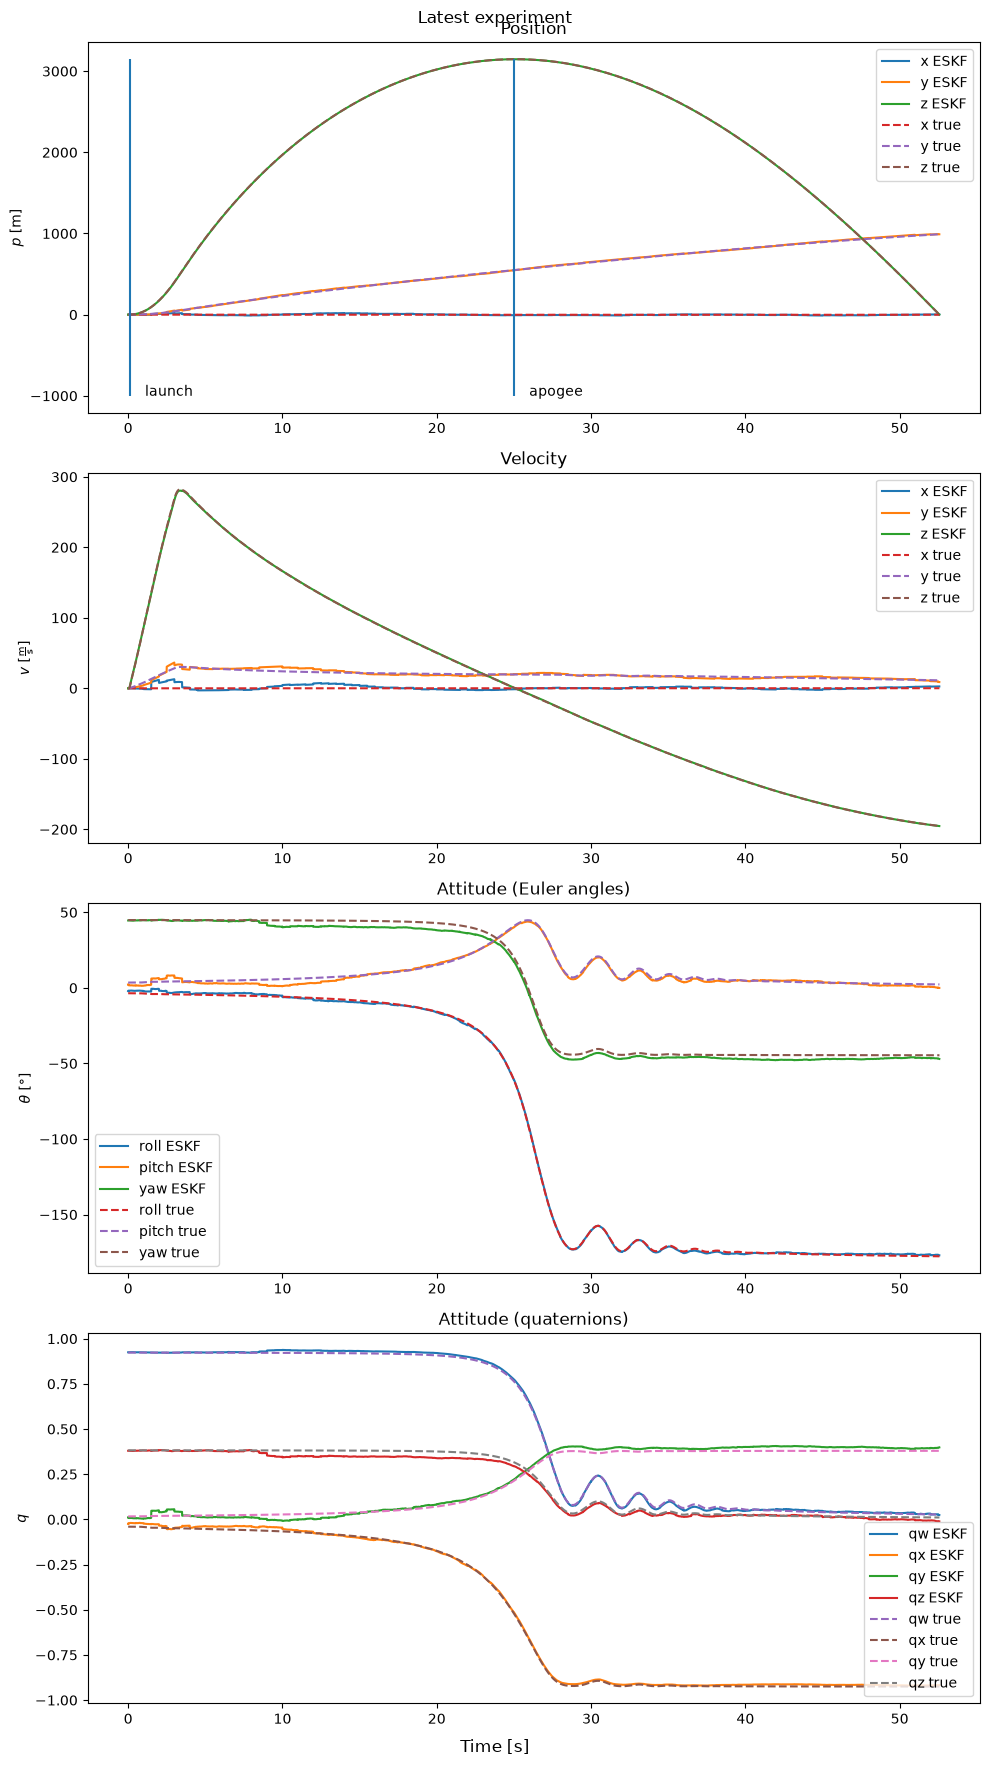

In [4]:


def plot_true_vs_ESKF(states, title=""):
    data = load_grund_truth()
    measurements = load_measurements()
    time = data["t"]
    positions_ESKF, velocities_ESKF, attitudes_ESKF, detected_launch_time, detected_apogee_time, _ = states
    euler_angles_ESKF = np.array([quaternion_to_euler_angles(attitude) for attitude in attitudes_ESKF])
    qw_true = data["qw"]
    qx_true = data["qx"]
    qy_true = data["qy"]
    qz_true = data["qz"]
    true_quaternions = np.array([[w, x, y, z] for w, x, y, z in zip(qw_true, qx_true, qy_true, qz_true)])
    true_euler_angles = np.array([quaternion_to_euler_angles(true_quaternion) for true_quaternion in true_quaternions])
    true_roll  = true_euler_angles[:, 0]
    true_pitch = true_euler_angles[:, 1]
    true_yaw   = true_euler_angles[:, 2]

    fig, axs=plt.subplots(4,figsize=(10, 18))
    axs[0].set_title("Position")
    axs[0].plot(measurements["t"], positions_ESKF[:, 0], label="x ESKF")
    axs[0].plot(measurements["t"], positions_ESKF[:, 1], label="y ESKF")
    axs[0].plot(measurements["t"], positions_ESKF[:, 2], label="z ESKF")
    axs[0].plot(time, data["x"], label="x true", ls="--")
    axs[0].plot(time, data["y"], label="y true", ls="--")
    axs[0].plot(time, data["z"], label="z true", ls="--")
    axs[0].set_ylabel(r"$p$ [m]")
    axs[0].vlines(detected_launch_time, min(data["z"])-1000, max(data["z"]))
    axs[0].vlines(detected_apogee_time, min(data["z"])-1000, max(data["z"]))
    axs[0].text(detected_launch_time+1, min(data["z"])-1000, "launch")
    axs[0].text(detected_apogee_time+1, min(data["z"])-1000, "apogee")    
    axs[1].set_title("Velocity")
    axs[1].plot(measurements["t"], velocities_ESKF[:, 0], label="x ESKF")
    axs[1].plot(measurements["t"], velocities_ESKF[:, 1], label="y ESKF")
    axs[1].plot(measurements["t"], velocities_ESKF[:, 2], label="z ESKF")
    axs[1].plot(time, data["vx"], label="x true", ls="--")
    axs[1].plot(time, data["vy"], label="y true", ls="--")
    axs[1].plot(time, data["vz"], label="z true", ls="--")
    axs[1].set_ylabel(r"$v$ [$\frac{\text{m}}{\text{s}}$]")
    # axs[1].hlines(0, data["t"][0], data["t"][-1], color="k")
    # axs[1].hlines(SPEED_OF_SOUND, data["t"][0], data["t"][-1], color="k", ls="--")    
    axs[2].set_title("Attitude (Euler angles)")
    axs[2].plot(measurements["t"], 180/np.pi*euler_angles_ESKF[:, 0], label="roll ESKF")
    axs[2].plot(measurements["t"], 180/np.pi*euler_angles_ESKF[:, 1], label="pitch ESKF")
    axs[2].plot(measurements["t"], 180/np.pi*euler_angles_ESKF[:, 2], label="yaw ESKF")
    axs[2].plot(time, 180/np.pi*true_roll, label="roll true", ls="--")
    axs[2].plot(time, 180/np.pi*true_pitch, label="pitch true", ls="--")
    axs[2].plot(time, 180/np.pi*true_yaw, label="yaw true", ls="--")
    axs[2].set_ylabel(r"$\theta$ [$\degree$]")
    axs[3].set_title("Attitude (quaternions)")
    axs[3].plot(measurements["t"], attitudes_ESKF[:, 0], label="qw ESKF")
    axs[3].plot(measurements["t"], attitudes_ESKF[:, 1], label="qx ESKF")
    axs[3].plot(measurements["t"], attitudes_ESKF[:, 2], label="qy ESKF")
    axs[3].plot(measurements["t"], attitudes_ESKF[:, 3], label="qz ESKF")
    axs[3].plot(time, true_quaternions[:, 0], label="qw true", ls="--")
    axs[3].plot(time, true_quaternions[:, 1], label="qx true", ls="--")
    axs[3].plot(time, true_quaternions[:, 2], label="qy true", ls="--")
    axs[3].plot(time, true_quaternions[:, 3], label="qz true", ls="--")
    axs[3].set_ylabel(r"$q$")
    for ax in axs.flatten():ax.legend()

    # axs[0].set_ylim(-100, 10000)
    fig.supxlabel("Time [s]")
    fig.suptitle("Latest experiment")
    fig.tight_layout()
    fig.savefig("ESKF_true_vs_estimated" + f"{title}" + ".png")
    
plot_true_vs_ESKF(ESKF_results)

/tmp/ipykernel_2104/2108622074.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  for ax in axs: ax.legend()


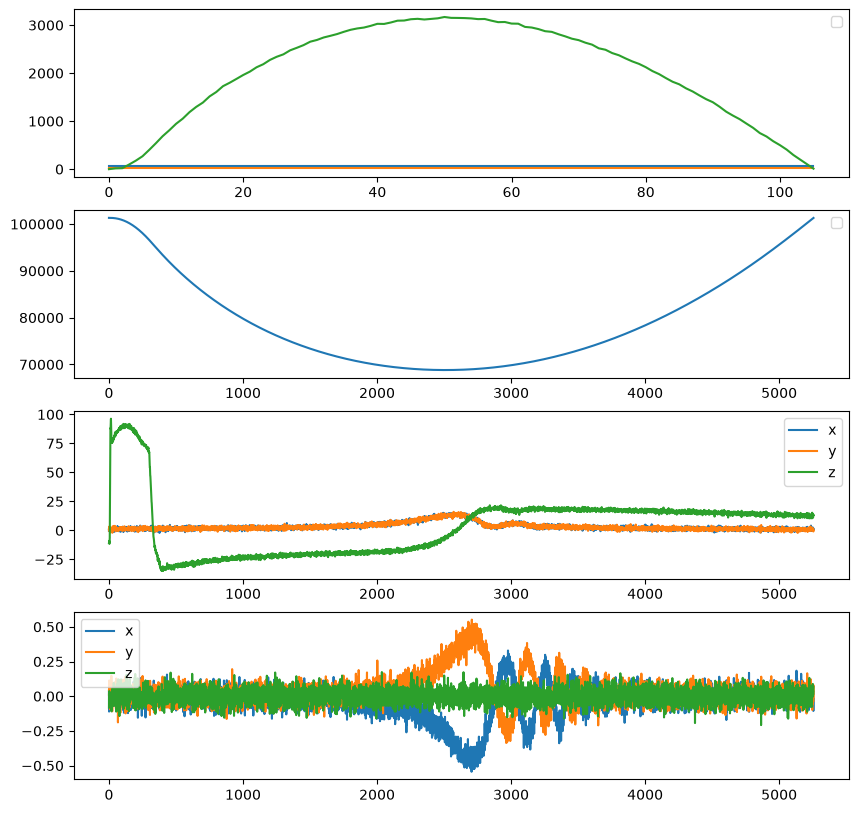

In [5]:
def plot_measurements():
    m = load_measurements()
    t = m["t"]
    latitude = [c for c in m["latitude"] if not np.isnan(c)]
    longitude = [c for c in m["longitude"] if not np.isnan(c)]
    altitude = [c for c in m["altitude"] if not np.isnan(c)]
    pressure = m["pressure"]
    ax = m["ax"]
    ay = m["ay"]
    az = m["az"]
    wx = m["wx"]
    wy = m["wy"]
    wz = m["wz"]

    fig, axs = plt.subplots(4, 1, figsize=(10, 10))
    axs[0].plot(latitude)
    axs[0].plot(longitude)
    axs[0].plot(altitude)

    axs[1].plot(pressure)

    axs[2].plot(ax, label="x")
    axs[2].plot(ay, label="y")
    axs[2].plot(az, label="z")
    axs[3].plot(wx, label="x")
    axs[3].plot(wy, label="y")
    axs[3].plot(wz, label="z")

    for ax in axs: ax.legend()
plot_measurements()

(5257,)


(0.0, 2.0)

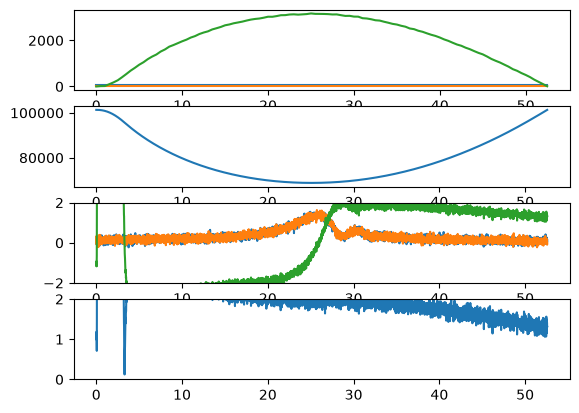

In [6]:
positions_ESKF, velocities_ESKF, attitudes_ESKF, detected_launch_time, detected_apogee_time, true_acc = ESKF_results
measurements = load_measurements()

t_gnss = [t for t,m in zip(measurements["t"], measurements["altitude"]) if not np.isnan(m)]
fig, axs=plt.subplots(4, 1)

axs[0].plot(t_gnss, [m for m in measurements["latitude"] if not np.isnan(m)])
axs[0].plot(t_gnss, [m for m in measurements["longitude"] if not np.isnan(m)])
axs[0].plot(t_gnss, [m for m in measurements["altitude"] if not np.isnan(m)])

axs[1].plot(measurements["t"], measurements["pressure"])

# axs[2].plot(measurements["t"], np.linalg.norm(true_acc, axis=1))
axs[2].plot(measurements["t"], measurements["ax"]/GRAVITY)
axs[2].plot(measurements["t"], measurements["ay"]/GRAVITY)
axs[2].plot(measurements["t"], measurements["az"]/GRAVITY)
axs[2].set_ylim(-2, 2)
# axs[2].plot(measurements["t"], )
a = np.array(list((measurements["ax"], measurements["ay"], measurements["az"])))
m = np.linalg.norm(a, axis=0)
print(m.shape)
axs[3].plot(measurements["t"], m/GRAVITY)
axs[3].set_ylim(0, 2)

In [7]:
from sim_src.quaternion_math import rotate_vector, inverse_quaternion
ground_truth = load_grund_truth()
qw = ground_truth["qw"][0]
qx = ground_truth["qx"][0]
qy = ground_truth["qy"][0]
qz = ground_truth["qz"][0]
q = np.array([qw,qx,qy,qz])
q
ax = measurements["ax"][0]
ay = measurements["ay"][0]
az = measurements["az"][0]
a = np.array([ax,ay,az])

r = rotate_vector(a, q)
print(q)
print(a)
r

[ 0.9230002  -0.04029906  0.01669242  0.3823192 ]
[ -0.05477985   1.1465641  -11.00691417]


array([ -0.84947846,  -0.19024546, -11.03231447])